In [2]:
# ==============================================================================
# HALO MASS FUNCTION SCRIPT - RESOLUTION COMPARISON (TNG50)
# ==============================================================================
import os
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# --- STYLE CONFIGURATION (As requested) ---
def matplotlib_default_config():
    """Returns the default dictionary configurations for publication-ready plots."""
    font = {'family' : 'serif', 'weight' : 'normal', 'size' : 14}
    rcnew = {
        "mathtext.fontset" : "cm", 
        "text.usetex": False, 
        'figure.frameon': True,
        'axes.linewidth': 2., 
        "axes.titlesize" : 20, 
        "axes.labelsize" : 20,
        "legend.fontsize" : 12, 
        'legend.fancybox': True, 
        'lines.linewidth': 2.5,
        'xtick.direction': 'in', 
        'ytick.direction': 'in',
        'xtick.top': True, 
        'ytick.right': True,
        'xtick.labelsize': 18, 
        'ytick.labelsize': 18
    }
    return font, rcnew

%matplotlib widget
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

In [3]:
# --- CONFIGURATION ---
SNAP_NUM = 25  # z = 3.0
HUBBLE_H = 0.6774
MASS_CONVERSION_FACTOR = 1e10 / HUBBLE_H

# Simulation paths from the server storage
SIM_PATHS = {
    'TNG50-4 (Low Res)': '/home/STORAGE/TNG50-4',
    'TNG50-3 (Med Res)': '/home/STORAGE/TNG50-3',
    'TNG50-2 (High Res)': '/home/STORAGE/TNG50-2'
}

# --- HELPER FUNCTION TO LOAD MASSES ---
def load_halo_masses_from_snapshot(base_path, snap_num):
    """
    Iterates over all HDF5 group catalog chunks for a given snapshot
    and extracts the M_200c mass of each FoF halo.
    """
    group_dir = f"groups_{snap_num:03d}"
    search_path = os.path.join(base_path, group_dir, f"fof_subhalo_tab_{snap_num:03d}.*.hdf5")
    file_list = glob.glob(search_path)
    
    if not file_list:
        print(f" [!] Warning: No group files found in {search_path}")
        return np.array([])

    masses_code_units = []
    
    # Read each chunk file to extract halo masses
    for h5_file in file_list:
        try:
            with h5py.File(h5_file, 'r') as f:
                # Check if the file contains the 'Group' block
                if 'Group' in f and 'Group_M_Crit200' in f['Group']:
                    m_crit = f['Group']['Group_M_Crit200'][:]
                    # Filter out halos with zero mass just in case
                    m_crit = m_crit[m_crit > 0]
                    masses_code_units.append(m_crit)
        except Exception as e:
            print(f"Error reading {h5_file}: {e}")
            
    if len(masses_code_units) == 0:
        return np.array([])
        
    # Concatenate all chunks and convert to physical solar masses
    all_masses = np.concatenate(masses_code_units)
    all_masses_msun = all_masses * MASS_CONVERSION_FACTOR
    return all_masses_msun

In [4]:
# --- LOAD DATA ---
print("Loading Halo Masses directly from STORAGE...")
mass_data = {}
for sim_name, sim_path in SIM_PATHS.items():
    print(f" -> Processing {sim_name}...")
    masses = load_halo_masses_from_snapshot(sim_path, SNAP_NUM)
    if len(masses) > 0:
        mass_data[sim_name] = masses
        print(f"    Extracted {len(masses):,} halos.")

Loading Halo Masses directly from STORAGE...
 -> Processing TNG50-4 (Low Res)...
    Extracted 25,539 halos.
 -> Processing TNG50-3 (Med Res)...
    Extracted 156,969 halos.
 -> Processing TNG50-2 (High Res)...
    Extracted 956,435 halos.


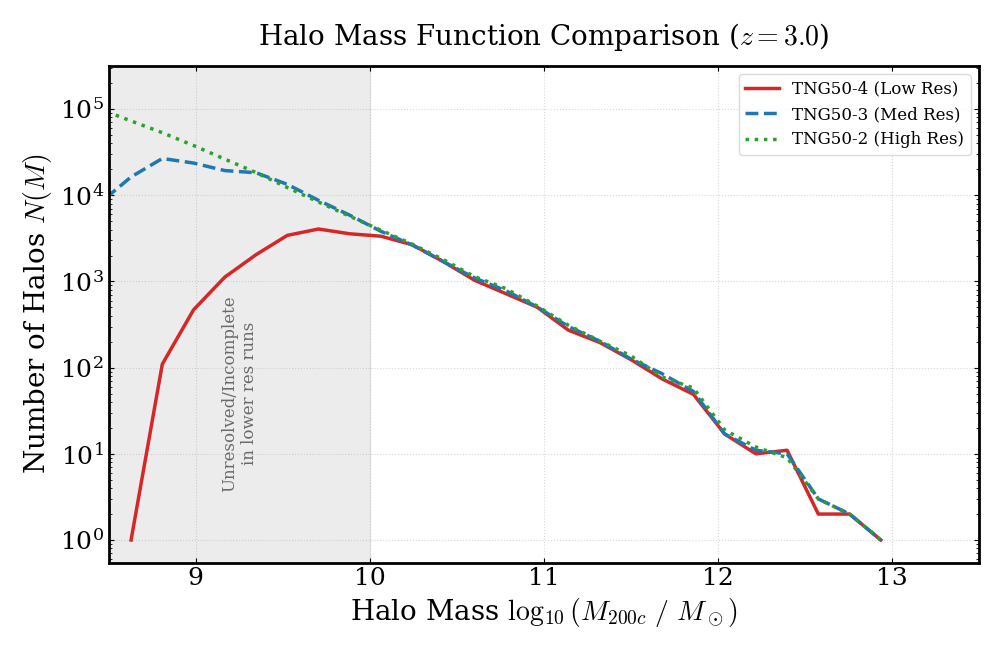

In [5]:
# --- PLOTTING ---
fig, ax = plt.subplots(figsize=(10, 6.5))

# Define aesthetics for the three resolutions
colors = ['tab:red', 'tab:blue', 'tab:green']
line_styles = ['-', '--', ':']

# Prepare mass bins (logarithmic)
min_log_mass = 8.0
max_log_mass = 15.0
bins = np.linspace(min_log_mass, max_log_mass, 40)
bin_centers = 0.5 * (bins[:-1] + bins[1:])

for idx, (sim_name, masses) in enumerate(mass_data.items()):
    c = colors[idx]
    ls = line_styles[idx]
    
    # Calculate log10 of mass
    log_masses = np.log10(masses)
    
    # Compute histogram (counts per mass bin)
    counts, _ = np.histogram(log_masses, bins=bins)
    
    # To properly plot a Mass Function, we use a logarithmic y-axis
    # We plot the counts replacing 0 with NaN so the line breaks gracefully
    plot_counts = np.where(counts > 0, counts, np.nan)
    
    ax.plot(bin_centers, plot_counts, color=c, ls=ls, lw=2.5, label=sim_name)

# --- AESTHETICS ---
ax.set_yscale('log')
ax.set_xlim(8.5, 13.5)

# Add grid and labels
ax.grid(True, ls=':', alpha=0.5)
ax.set_xlabel(r'Halo Mass $\log_{10}(M_{200c} \ / \ M_\odot)$')
ax.set_ylabel(r'Number of Halos $N(M)$')
ax.set_title(r'Halo Mass Function Comparison ($z=3.0$)', pad=15)

# Legend
ax.legend(loc='upper right', frameon=True, fontsize=12, edgecolor='lightgray')

# Add a vertical shaded region to highlight where lower resolutions start to fail
# You can adjust this xmin/xmax after inspecting the plot
ax.axvspan(8.5, 10.0, color='gray', alpha=0.15, zorder=0)
ax.text(9.25, 50, 'Unresolved/Incomplete\nin lower res runs', 
        rotation=90, va='center', ha='center', fontsize=12, color='dimgray')

plt.tight_layout()
plt.show()

In [6]:
# ==============================================================================
# HALO COUNTS IN SPECIFIC MASS BINS
# ==============================================================================

# Create 5 log-spaced bins between 10^10 and 10^13 M_sun (requires 6 edges)
mass_edges = np.logspace(10, 13, 5)

print("="*60)
print("   CONTAGEM DE HALOS RESOLVIDOS (10^10 a 10^13 M_sun)")
print("="*60)

# Iterate over the previously loaded data
for sim_name, masses in mass_data.items():
    print(f"\nSimulação: {sim_name}")
    print("-" * 50)
    
    # Calculate histogram to get counts per bin
    counts, _ = np.histogram(masses, bins=mass_edges)
    
    # Print the results with cleanly formatted log exponents
    for i in range(len(counts)):
        log_low = np.log10(mass_edges[i])
        log_high = np.log10(mass_edges[i+1])
        
        print(f"Bin [10^{log_low:.1f} - 10^{log_high:.1f}] M_sun : {counts[i]:>6} halos")

print("\n" + "="*60)

   CONTAGEM DE HALOS RESOLVIDOS (10^10 a 10^13 M_sun)

Simulação: TNG50-4 (Low Res)
--------------------------------------------------
Bin [10^10.0 - 10^10.8] M_sun :   8537 halos
Bin [10^10.8 - 10^11.5] M_sun :   1477 halos
Bin [10^11.5 - 10^12.2] M_sun :    197 halos
Bin [10^12.2 - 10^13.0] M_sun :     19 halos

Simulação: TNG50-3 (Med Res)
--------------------------------------------------
Bin [10^10.0 - 10^10.8] M_sun :   8871 halos
Bin [10^10.8 - 10^11.5] M_sun :   1564 halos
Bin [10^11.5 - 10^12.2] M_sun :    225 halos
Bin [10^12.2 - 10^13.0] M_sun :     19 halos

Simulação: TNG50-2 (High Res)
--------------------------------------------------
Bin [10^10.0 - 10^10.8] M_sun :   9225 halos
Bin [10^10.8 - 10^11.5] M_sun :   1605 halos
Bin [10^11.5 - 10^12.2] M_sun :    232 halos
Bin [10^12.2 - 10^13.0] M_sun :     19 halos



In [7]:
# ==============================================================================
# CELL A — Test different binning strategies and print counts
# Goal: find bins with enough halos for variance but physically meaningful
# We test: equal-width log, quantile-based, and a manually tuned proposal
# ==============================================================================

import numpy as np

# Use the already-loaded mass_data from the cells above
# Focus on TNG50-2 since it's the target simulation
target_sim = 'TNG50-2 (High Res)'
masses_tng2 = mass_data[target_sim]

# Restrict to the resolved range: 10^10 to 10^13 M_sun
mask_resolved = (masses_tng2 >= 1e10) & (masses_tng2 <= 1e13)
masses_resolved = masses_tng2[mask_resolved]
log_masses = np.log10(masses_resolved)

print(f"Total resolved halos in TNG50-2 (10^10 to 10^13): {len(masses_resolved):,}")
print(f"Log-mass range: [{log_masses.min():.3f}, {log_masses.max():.3f}]\n")

# ------------------------------------------------------------------------------
# STRATEGY 1: Equal-width log bins (N bins between 10 and 13)
# Test N = 4, 5, 6, 7, 8
# ------------------------------------------------------------------------------
print("=" * 65)
print("STRATEGY 1: Equal-width log bins")
print("=" * 65)

for n_bins in [4, 5, 6, 7, 8]:
    edges = np.linspace(10.0, 13.0, n_bins + 1)
    counts, _ = np.histogram(log_masses, bins=edges)
    print(f"\n  {n_bins} bins:")
    for i in range(n_bins):
        flag = ""
        if counts[i] < 50:
            flag = "  ← sparse (exhaustive)"
        elif counts[i] < 200:
            flag = "  ← moderate variance"
        print(f"    [10^{edges[i]:.2f} - 10^{edges[i+1]:.2f}] : "
              f"{counts[i]:>6,} halos{flag}")

Total resolved halos in TNG50-2 (10^10 to 10^13): 11,081
Log-mass range: [10.000, 12.949]

STRATEGY 1: Equal-width log bins

  4 bins:
    [10^10.00 - 10^10.75] :  9,225 halos
    [10^10.75 - 10^11.50] :  1,605 halos
    [10^11.50 - 10^12.25] :    232 halos
    [10^12.25 - 10^13.00] :     19 halos  ← sparse (exhaustive)

  5 bins:
    [10^10.00 - 10^10.60] :  8,370 halos
    [10^10.60 - 10^11.20] :  2,149 halos
    [10^11.20 - 10^11.80] :    469 halos
    [10^11.80 - 10^12.40] :     86 halos  ← moderate variance
    [10^12.40 - 10^13.00] :      7 halos  ← sparse (exhaustive)

  6 bins:
    [10^10.00 - 10^10.50] :  7,666 halos
    [10^10.50 - 10^11.00] :  2,466 halos
    [10^11.00 - 10^11.50] :    698 halos
    [10^11.50 - 10^12.00] :    214 halos
    [10^12.00 - 10^12.50] :     32 halos  ← sparse (exhaustive)
    [10^12.50 - 10^13.00] :      5 halos  ← sparse (exhaustive)

  7 bins:
    [10^10.00 - 10^10.43] :  7,009 halos
    [10^10.43 - 10^10.86] :  2,664 halos
    [10^10.86 - 10^11.

In [8]:
# ==============================================================================
# CELL B — Strategy 2: Quantile-based bins
# Each bin contains roughly the same NUMBER of halos
# This maximises variance uniformly across bins
# ==============================================================================
print("=" * 65)
print("STRATEGY 2: Quantile-based bins (equal halo count per bin)")
print("=" * 65)

for n_bins in [4, 5, 6]:
    quantiles = np.linspace(0, 100, n_bins + 1)
    edges = np.percentile(log_masses, quantiles)
    counts, _ = np.histogram(log_masses, bins=edges)
    print(f"\n  {n_bins} bins (each ~{len(masses_resolved)//n_bins:,} halos):")
    for i in range(n_bins):
        print(f"    [10^{edges[i]:.3f} - 10^{edges[i+1]:.3f}] : "
              f"{counts[i]:>6,} halos")

STRATEGY 2: Quantile-based bins (equal halo count per bin)

  4 bins (each ~2,770 halos):
    [10^10.000 - 10^10.126] :  2,770 halos
    [10^10.126 - 10^10.298] :  2,770 halos
    [10^10.298 - 10^10.589] :  2,770 halos
    [10^10.589 - 10^12.949] :  2,771 halos

  5 bins (each ~2,216 halos):
    [10^10.000 - 10^10.100] :  2,216 halos
    [10^10.100 - 10^10.225] :  2,216 halos
    [10^10.225 - 10^10.393] :  2,216 halos
    [10^10.393 - 10^10.683] :  2,216 halos
    [10^10.683 - 10^12.949] :  2,217 halos

  6 bins (each ~1,846 halos):
    [10^10.000 - 10^10.081] :  1,847 halos
    [10^10.081 - 10^10.180] :  1,847 halos
    [10^10.180 - 10^10.298] :  1,846 halos
    [10^10.298 - 10^10.468] :  1,847 halos
    [10^10.468 - 10^10.752] :  1,847 halos
    [10^10.752 - 10^12.949] :  1,847 halos


In [9]:
# ==============================================================================
# CELL C — Strategy 3: Physically motivated proposal
# Bins reflect distinct physical regimes at z=3:
#   - Sub-L*  galaxies (dominated by IGM / CGM interface)
#   - L*      galaxies (Milky-Way progenitors)
#   - Groups  (rare, always exhaustive)
#   - Clusters (proto-clusters, census)
# Tuned so that bins 1-3 have >> 150 halos (good variance)
# and bins 4+ are collected exhaustively
# ==============================================================================
print("=" * 65)
print("STRATEGY 3: Physically motivated proposal")
print("=" * 65)

proposals = [
    # (label, edges_log10)
    ("Proposal A — 5 bins", [10.0, 10.5, 11.0, 11.5, 12.0, 13.0]),
    ("Proposal B — 6 bins", [10.0, 10.4, 10.8, 11.2, 11.6, 12.2, 13.0]),
    ("Proposal C — 7 bins", [10.0, 10.3, 10.6, 11.0, 11.4, 11.8, 12.3, 13.0]),
]

EXHAUSTIVE_THRESH = 50   # bins below this -> exhaustive census
N_TARGET = 150           # desired sample per rich bin

for label, edges in proposals:
    counts, _ = np.histogram(log_masses, bins=edges)
    print(f"\n  {label}:")
    for i, c in enumerate(counts):
        mode = "EXHAUSTIVE" if c < EXHAUSTIVE_THRESH else (
               "moderate ⚠" if c < N_TARGET * 1.5 else "rich ✓")
        print(f"    [10^{edges[i]:.1f} - 10^{edges[i+1]:.1f}] : "
              f"{c:>6,} halos  [{mode}]")

STRATEGY 3: Physically motivated proposal

  Proposal A — 5 bins:
    [10^10.0 - 10^10.5] :  7,666 halos  [rich ✓]
    [10^10.5 - 10^11.0] :  2,466 halos  [rich ✓]
    [10^11.0 - 10^11.5] :    698 halos  [rich ✓]
    [10^11.5 - 10^12.0] :    214 halos  [moderate ⚠]
    [10^12.0 - 10^13.0] :     37 halos  [EXHAUSTIVE]

  Proposal B — 6 bins:
    [10^10.0 - 10^10.4] :  6,710 halos  [rich ✓]
    [10^10.4 - 10^10.8] :  2,740 halos  [rich ✓]
    [10^10.8 - 10^11.2] :  1,069 halos  [rich ✓]
    [10^11.2 - 10^11.6] :    381 halos  [rich ✓]
    [10^11.6 - 10^12.2] :    159 halos  [moderate ⚠]
    [10^12.2 - 10^13.0] :     22 halos  [EXHAUSTIVE]

  Proposal C — 7 bins:
    [10^10.0 - 10^10.3] :  5,566 halos  [rich ✓]
    [10^10.3 - 10^10.6] :  2,804 halos  [rich ✓]
    [10^10.6 - 10^11.0] :  1,762 halos  [rich ✓]
    [10^11.0 - 10^11.4] :    624 halos  [rich ✓]
    [10^11.4 - 10^11.8] :    232 halos  [rich ✓]
    [10^11.8 - 10^12.3] :     77 halos  [moderate ⚠]
    [10^12.3 - 10^13.0] :     16 

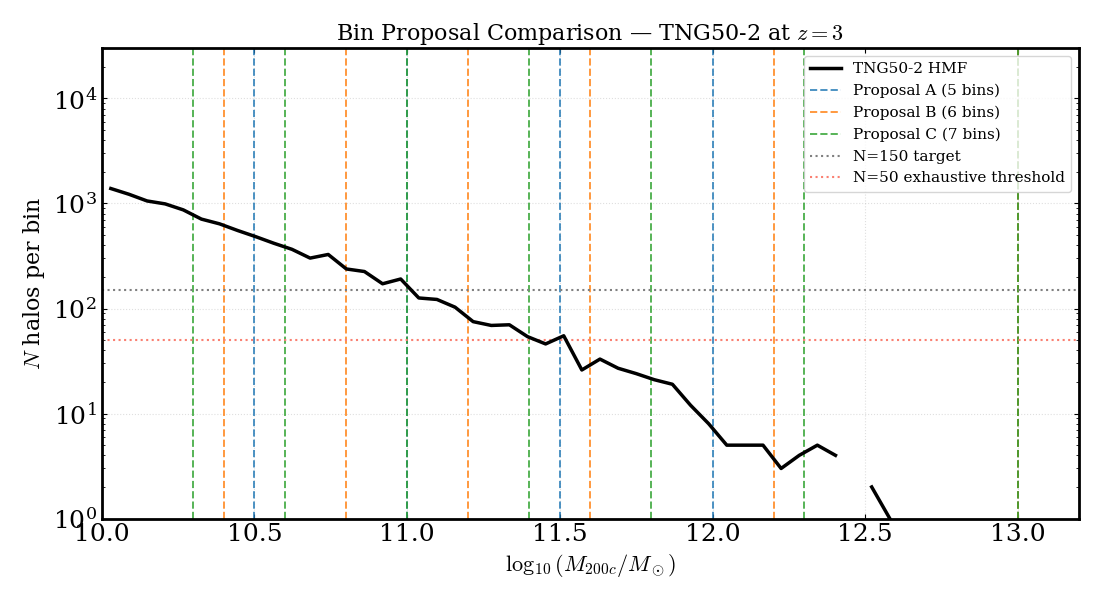

In [10]:
# ==============================================================================
# CELL D — Visual comparison: overlay all bin proposals on the HMF
# Makes it easy to see where bin edges fall relative to the distribution
# ==============================================================================

fig, ax = plt.subplots(figsize=(11, 6))

# Plot TNG50-2 HMF as background
bins_plot = np.linspace(10.0, 13.5, 60)
bin_centers_plot = 0.5 * (bins_plot[:-1] + bins_plot[1:])
counts_plot, _ = np.histogram(log_masses, bins=bins_plot)
counts_plot = np.where(counts_plot > 0, counts_plot, np.nan)

ax.plot(bin_centers_plot, counts_plot, 'k-', lw=2.5, label='TNG50-2 HMF', zorder=5)
ax.set_yscale('log')

# Overlay the bin edges for each proposal as vertical lines
proposal_colors = ['tab:blue', 'tab:orange', 'tab:green']
proposal_edges = [
    [10.0, 10.5, 11.0, 11.5, 12.0, 13.0],          # A
    [10.0, 10.4, 10.8, 11.2, 11.6, 12.2, 13.0],     # B
    [10.0, 10.3, 10.6, 11.0, 11.4, 11.8, 12.3, 13.0], # C
]
proposal_labels = ['Proposal A (5 bins)', 'Proposal B (6 bins)', 'Proposal C (7 bins)']

for edges, color, label in zip(proposal_edges, proposal_colors, proposal_labels):
    for i, edge in enumerate(edges):
        ax.axvline(edge, color=color, lw=1.4, ls='--', alpha=0.8,
                   label=label if i == 0 else "")

# Reference line for N=150 (target per bin)
ax.axhline(150, color='gray', ls=':', lw=1.5, label='N=150 target')
ax.axhline(50,  color='salmon', ls=':', lw=1.5, label='N=50 exhaustive threshold')

ax.set_xlim(10.0, 13.2)
ax.set_ylim(1, 3e4)
ax.set_xlabel(r'$\log_{10}(M_{200c} / M_\odot)$', fontsize=16)
ax.set_ylabel(r'$N$ halos per bin', fontsize=16)
ax.set_title('Bin Proposal Comparison — TNG50-2 at $z=3$', fontsize=16)
ax.legend(fontsize=11, loc='upper right')
ax.grid(True, ls=':', alpha=0.4)

plt.tight_layout()
plt.show()

In [ ]:
# Teste rápido: um único skewer, modo None vs DLAs
import fake_spectra.spectra as spectra
import numpy as np

# Halo 0 (o mais massivo), eixo X, b=0
cofm = np.array([halo_cm], dtype=np.float64)  # centro do halo
axis = np.array([1], dtype=np.int32)           # eixo X

# Modo None (sem filtro)
ss_none = spectra.Spectra(25, base_path, cofm=cofm, axis=axis,
                          res=10.0, reload_file=True, quiet=True,
                          filter_mode="None", units=units,
                          savefile="test_none.hdf5")
colden_none = ss_none.get_col_density("H", 1)[0]
print(f"Mode None:  total N_HI = {np.sum(colden_none):.3e}")
print(f"  Max pixel = {np.max(colden_none):.3e}")
print(f"  Pixels > 1e17: {np.sum(colden_none > 1e17)}")
print(f"  Pixels > 1e19: {np.sum(colden_none > 1e19)}")

# Modo DLAs (com filtro)
ss_dla = spectra.Spectra(25, base_path, cofm=cofm, axis=axis,
                         res=10.0, reload_file=True, quiet=True,
                         filter_mode="DLAs", units=units,
                         savefile="test_dla.hdf5")
colden_dla = ss_dla.get_col_density("H", 1)[0]
print(f"\nMode DLAs:  total N_HI = {np.sum(colden_dla):.3e}")
print(f"  Max pixel = {np.max(colden_dla):.3e}")

108000